<a href="https://colab.research.google.com/github/14-169-RaisyaSyifaSaleh/Kelompok11_Studio2/blob/main/Studio2_123140169_123140212.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Kompetisi Klasifikasi Sampah**

---

### **1. Anggota Kelompok**
* **Anggota 1:** [Raisya Syifa Saleh] - [123140169]
* **Anggota 2:** [Diva Amelia Saputri] - [123140212]

---

### **2. Deskripsi Tugas**
Bangun model klasifikasi citra yang menerima satu foto sampah dan memprediksi salah satu dari lima kelas di bawah. Anda bebas memilih pendekatan: CNN from scratch seperti di Pertemuan 4, arsitektur modern dari Pertemuan 5, atau fine-tuning backbone pretrained ImageNet sesuai materi Studio 2. Data tambahan dari luar juga diperbolehkan.

Kelompok tidak pernah melihat validation set. Asisten dosen yang menjalankan model (model.pth) kelompok Anda pada validation set menggunakan skrip evaluate.py yang sama persis dengan yang ada di starter kit, lalu mencatat skornya di Google Sheets skor kelompok.

---



In [1]:
import os
import sys
import torch
import torchvision
from PIL import Image

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
    print("Memori GPU:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU belum aktif. Periksa Runtime > Change runtime type.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU tersedia: True
Nama GPU: Tesla T4
Memori GPU: 14.56 GB


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os

dataset_folder = "/content/drive/MyDrive/Studio2_Kelompok11"

print("Lokasi dataset:", dataset_folder)
print("Folder ditemukan:", os.path.exists(dataset_folder))

if os.path.exists(dataset_folder):
    print("\nIsi folder:")
    for item in os.listdir(dataset_folder):
        print("-", item)
else:
    print("Folder belum ditemukan. Periksa lokasi Google Drive.")

Lokasi dataset: /content/drive/MyDrive/Studio2_Kelompok11
Folder ditemukan: True

Isi folder:
- dataset_mahasiswa


In [4]:
import os

dataset_folder = "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"

print("Lokasi dataset:", dataset_folder)
print("Folder ditemukan:", os.path.exists(dataset_folder))

if os.path.exists(dataset_folder):
    print("\nIsi folder dataset_mahasiswa:")
    for item in os.listdir(dataset_folder):
        print("-", item)
else:
    print("Folder tidak ditemukan.")

Lokasi dataset: /content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa
Folder ditemukan: True

Isi folder dataset_mahasiswa:
- train_sources.csv
- BACA_SAYA.txt
- starter_kit
- train
- local_split
- outputs


In [5]:
from pathlib import Path

dataset_folder = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)

train_dir = dataset_folder / "train"

expected_classes = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam"
]

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("Folder train ditemukan:", train_dir.exists())
print("\nIsi folder train:")

if train_dir.exists():
    for item in sorted(train_dir.iterdir()):
        print("-", item.name)

    print("\nJumlah gambar per kelas:")

    for class_name in expected_classes:
        class_dir = train_dir / class_name

        if class_dir.exists():
            images = [
                file for file in class_dir.rglob("*")
                if file.is_file()
                and file.suffix.lower() in image_extensions
            ]

            print(f"{class_name}: {len(images)} gambar")
        else:
            print(f"{class_name}: FOLDER TIDAK DITEMUKAN")
else:
    print("Folder train tidak ditemukan. Periksa kembali lokasi dataset.")

Folder train ditemukan: True

Isi folder train:
- botol_plastik
- gelas_plastik
- kertas_kardus
- saset_kemasan
- styrofoam

Jumlah gambar per kelas:
botol_plastik: 523 gambar
gelas_plastik: 521 gambar
kertas_kardus: 365 gambar
saset_kemasan: 673 gambar
styrofoam: 671 gambar


### Visualisasi Dataset

Dataset yang digunakan terdiri dari lima kelas sampah, yaitu *botol_plastik*, *gelas_plastik*, *kertas_kardus*, *saset_kemasan*, dan *styrofoam*. Sebelum proses pelatihan model, beberapa citra dari setiap kelas ditampilkan untuk mengamati karakteristik visual objek yang akan diklasifikasikan. Visualisasi ini juga membantu memberikan gambaran mengenai variasi bentuk, warna, dan tampilan objek dalam dataset.

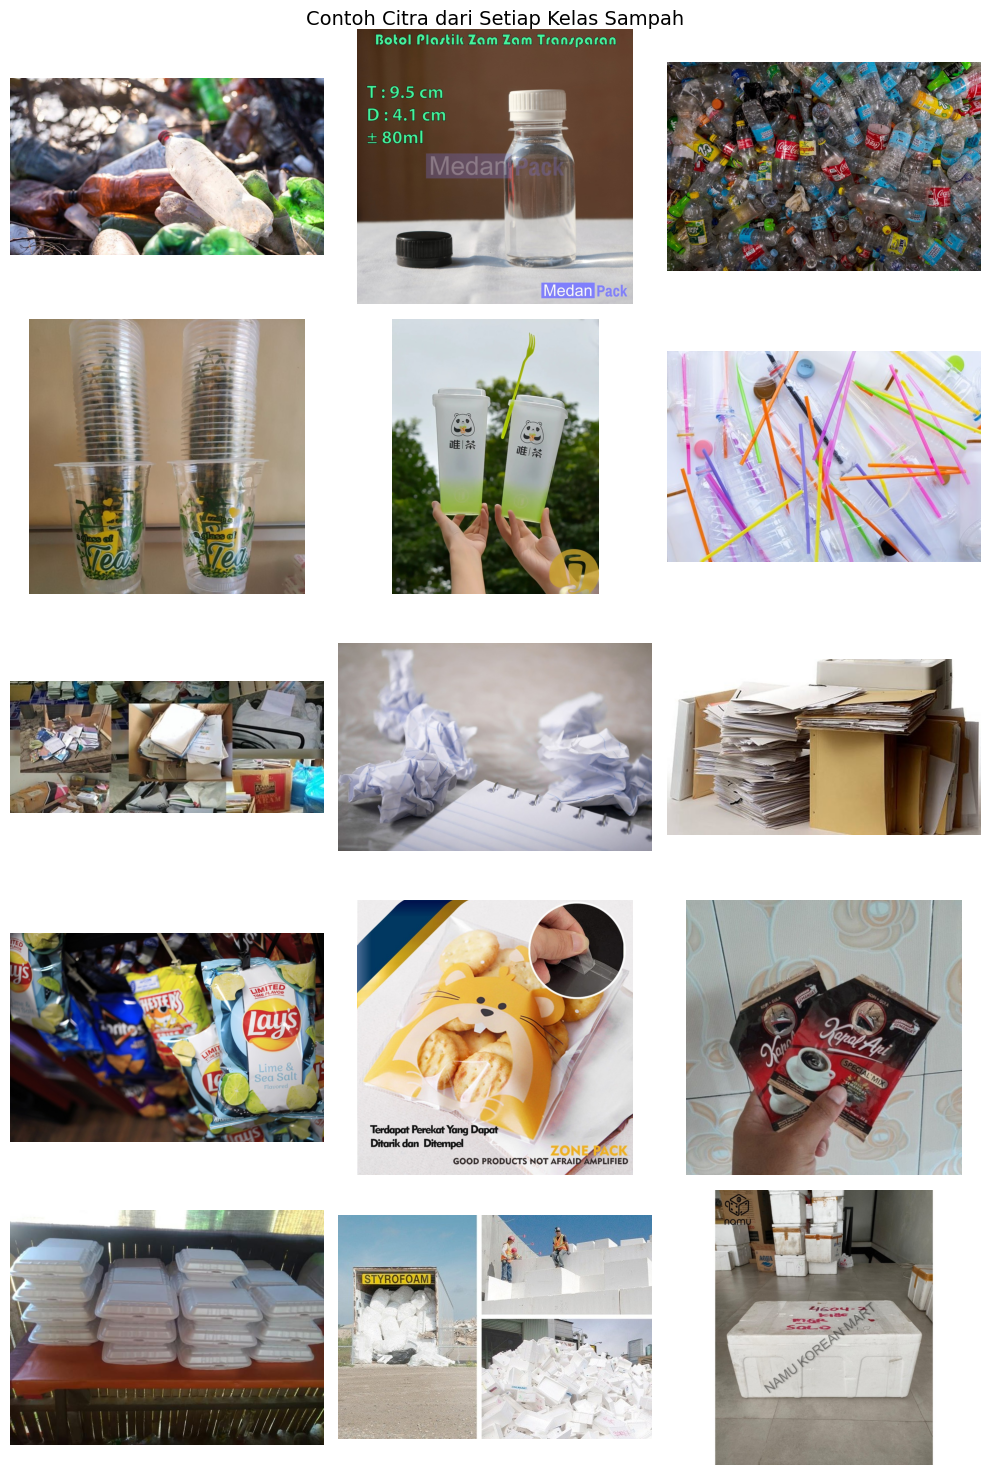

In [6]:

import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATASET_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)
TRAIN_DIR = DATASET_DIR / "train"

CLASSES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam",
]

random.seed(42)

fig, axes = plt.subplots(
    nrows=len(CLASSES),
    ncols=3,
    figsize=(10, 15)
)

for row, class_name in enumerate(CLASSES):
    class_dir = TRAIN_DIR / class_name
    image_paths = sorted(class_dir.glob("*.jpg"))

    samples = random.sample(image_paths, min(3, len(image_paths)))

    for col in range(3):
        ax = axes[row, col]
        ax.axis("off")

        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert("RGB"))

            if col == 0:
                ax.set_ylabel(
                    class_name,
                    fontsize=10,
                    rotation=90,
                    labelpad=12
                )

plt.suptitle(
    "Contoh Citra dari Setiap Kelas Sampah",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [7]:
from pathlib import Path

starter_dir = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/"
    "dataset_mahasiswa/starter_kit"
)

print("Starter kit ditemukan:", starter_dir.exists())

if starter_dir.exists():
    print("\nDaftar file starter kit:")

    for item in sorted(starter_dir.rglob("*")):
        if item.is_file():
            print("-", item.relative_to(starter_dir))

Starter kit ditemukan: True

Daftar file starter kit:
- README_TEMPLATE.md
- evaluate.py
- submission/__pycache__/model.cpython-313.pyc
- submission/model.py
- train_baseline.py


In [8]:
from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)

files_to_read = [
    dataset_dir / "BACA_SAYA.txt",
    dataset_dir / "starter_kit" / "submission" / "model.py",
    dataset_dir / "starter_kit" / "README_TEMPLATE.md",
]

for file_path in files_to_read:
    print("\n" + "=" * 60)
    print("FILE:", file_path.name)
    print("=" * 60)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File tidak ditemukan:", file_path)



FILE: BACA_SAYA.txt
STUDIO 2 — KOMPETISI KLASIFIKASI SAMPAH
Deep Learning (IF25-40401) · Teknik Informatika ITERA · Ganjil 2026/2027

Halaman kompetisi (aturan, jadwal, penilaian):
  https://informatika-itera.github.io/deep-learning-IF25-40401/studio-2/

Isi:
  train/<kelas>/*.jpg   train set, 5 kelas:
                        0 botol_plastik, 1 gelas_plastik, 2 kertas_kardus,
                        3 saset_kemasan, 4 styrofoam
  train_sources.csv     sumber (URL) setiap gambar
  starter_kit/          evaluate.py (skrip evaluasi resmi), train_baseline.py,
                        submission/model.py (contoh), README_TEMPLATE.md

Mulai cepat:
  cd starter_kit
  python train_baseline.py --data ../train --epochs 8
  python evaluate.py --submission ./submission --data ./my_val

Validation set tidak dibagikan. Asisten dosen menjalankan model.pth kelompok
Anda dengan evaluate.py yang sama pada setiap tenggat preview.

Gambar dikumpulkan dari internet untuk keperluan pendidikan non-komersial.

In [9]:
from pathlib import Path

starter_dir = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/"
    "dataset_mahasiswa/starter_kit"
)

for filename in ["train_baseline.py", "evaluate.py"]:
    file_path = starter_dir / filename

    print("\n" + "=" * 60)
    print(f"FILE: {filename}")
    print("=" * 60)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File tidak ditemukan:", file_path)


FILE: train_baseline.py
"""Baseline sederhana Studio 2: fine-tuning ResNet-18 (pretrained ImageNet).

Titik awal saja — kelompok diharapkan melakukan eksperimen sendiri
(backbone lain, augmentasi, freezing, scheduler, data tambahan, dll.).

    python train_baseline.py --data ./train --epochs 8
    python train_baseline.py --data ./train --epochs 8 --scratch   # tanpa bobot pretrained

Hasil: submission/model.pth + folder my_val/ (split validasi lokal 15%)
       yang bisa langsung diuji dengan:
    python evaluate.py --submission ./submission --data ./my_val
"""
import argparse
import random
import shutil
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

from submission.model import get_model, get_transform


def make_local_split(src, dst, frac, seed):
    """Salin 15% gambar per kelas dari train ke my_val/ (sekali saja), sisanya ke my_train/."""
    dst_tr, dst_va = Path(dst) / "

In [10]:
from pathlib import Path
from collections import Counter

dataset_dir = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)
train_dir = dataset_dir / "train"

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("Format gambar per kelas:\n")

for class_dir in sorted(train_dir.iterdir()):
    if not class_dir.is_dir():
        continue

    extensions = Counter(
        p.suffix.lower()
        for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    print(f"{class_dir.name}:")
    for ext, count in sorted(extensions.items()):
        print(f"  {ext}: {count}")

Format gambar per kelas:

botol_plastik:
  .jpg: 523
gelas_plastik:
  .jpg: 521
kertas_kardus:
  .jpg: 365
saset_kemasan:
  .jpg: 673
styrofoam:
  .jpg: 671


In [11]:

from pathlib import Path
from collections import Counter
import random
import shutil

# Lokasi dataset di Google Drive
DATASET_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)
SOURCE_DIR = DATASET_DIR / "train"

# Lokasi hasil pembagian data
SPLIT_DIR = DATASET_DIR / "local_split"
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"

# Pengaturan pembagian data
SEED = 42
VAL_RATIO = 0.15

CLASSES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Pastikan dataset sumber tersedia
assert SOURCE_DIR.exists(), (
    f"Folder dataset tidak ditemukan: {SOURCE_DIR}"
)

# Jangan menimpa pembagian sebelumnya secara tidak sengaja
if SPLIT_DIR.exists():
    # Periksa apakah hasil pembagian sebelumnya sudah lengkap
    if (
        TRAIN_DIR.is_dir()
        and VAL_DIR.is_dir()
        and all((TRAIN_DIR / c).is_dir() for c in CLASSES)
        and all((VAL_DIR / c).is_dir() for c in CLASSES)
    ):
        print("Folder hasil pembagian sudah ada.")
        print("Menggunakan hasil pembagian sebelumnya.")

    else:
        raise FileExistsError(
            f"Folder {SPLIT_DIR} sudah ada, tetapi hasil "
            "pembagian belum lengkap. Periksa folder sebelumnya "
            "sebelum membuat ulang."
        )

else:
    random.seed(SEED)

    # Pastikan semua kelas ditemukan
    for class_name in CLASSES:
        class_dir = SOURCE_DIR / class_name
        assert class_dir.is_dir(), (
            f"Folder kelas tidak ditemukan: {class_dir}"
        )

    # Buat folder hasil pembagian
    for class_name in CLASSES:
        (TRAIN_DIR / class_name).mkdir(parents=True)
        (VAL_DIR / class_name).mkdir(parents=True)

    # Bagi gambar di setiap kelas
    for class_name in CLASSES:
        class_dir = SOURCE_DIR / class_name

        images = sorted(
            p for p in class_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        random.shuffle(images)

        val_count = round(len(images) * VAL_RATIO)
        val_images = images[:val_count]
        train_images = images[val_count:]

        for image_path in train_images:
            shutil.copy2(
                image_path,
                TRAIN_DIR / class_name / image_path.name
            )

        for image_path in val_images:
            shutil.copy2(
                image_path,
                VAL_DIR / class_name / image_path.name
            )

# Tampilkan hasil pembagian
print("HASIL PEMBAGIAN DATASET")
print("-" * 45)

total_train = 0
total_val = 0

for class_name in CLASSES:
    n_train = len(list((TRAIN_DIR / class_name).glob("*")))
    n_val = len(list((VAL_DIR / class_name).glob("*")))

    total_train += n_train
    total_val += n_val

    print(
        f"{class_name:18s} | "
        f"Train: {n_train:4d} | Val: {n_val:3d}"
    )

print("-" * 45)
print(f"Total training   : {total_train}")
print(f"Total validasi   : {total_val}")
print(f"Total keseluruhan: {total_train + total_val}")


Folder hasil pembagian sudah ada.
Menggunakan hasil pembagian sebelumnya.
HASIL PEMBAGIAN DATASET
---------------------------------------------
botol_plastik      | Train:  445 | Val:  78
gelas_plastik      | Train:  443 | Val:  78
kertas_kardus      | Train:  310 | Val:  55
saset_kemasan      | Train:  572 | Val: 101
styrofoam          | Train:  570 | Val: 101
---------------------------------------------
Total training   : 2340
Total validasi   : 413
Total keseluruhan: 2753


In [12]:

from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)

for folder in ["train", "val"]:
    split_path = DATASET_DIR / "local_split" / folder
    print(f"{folder}: {split_path.exists()}")

    if split_path.exists():
        for class_dir in sorted(split_path.iterdir()):
            if class_dir.is_dir():
                print(f"  {class_dir.name}: {len(list(class_dir.glob('*')))} file")


train: True
  botol_plastik: 445 file
  gelas_plastik: 443 file
  kertas_kardus: 310 file
  saset_kemasan: 572 file
  styrofoam: 570 file
val: True
  botol_plastik: 78 file
  gelas_plastik: 78 file
  kertas_kardus: 55 file
  saset_kemasan: 101 file
  styrofoam: 101 file


In [13]:

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU belum aktif. Buka Runtime > Change runtime type,")
    print("lalu pilih GPU pada Hardware accelerator.")


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU tersedia: True
Nama GPU: Tesla T4


In [14]:

from pathlib import Path
import torch
import torchvision
from google.colab import drive

# Hubungkan Google Drive
drive.mount("/content/drive")

# Lokasi dataset yang sudah dibagi menjadi train dan val
DATASET_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa"
)
SPLIT_DIR = DATASET_DIR / "local_split"
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"

# Lokasi penyimpanan hasil training
OUTPUT_DIR = DATASET_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam",
]

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Perangkat:", "GPU" if torch.cuda.is_available() else "CPU")
print("Folder train tersedia:", TRAIN_DIR.exists())
print("Folder val tersedia:", VAL_DIR.exists())
print("Folder hasil:", OUTPUT_DIR)

if not TRAIN_DIR.exists() or not VAL_DIR.exists():
    raise FileNotFoundError(
        "Folder train/val tidak ditemukan. Periksa lokasi dataset."
    )

for kelas in CLASSES:
    jumlah_train = len(list((TRAIN_DIR / kelas).glob("*.jpg")))
    jumlah_val = len(list((VAL_DIR / kelas).glob("*.jpg")))
    print(f"{kelas}: train={jumlah_train}, val={jumlah_val}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Perangkat: GPU
Folder train tersedia: True
Folder val tersedia: True
Folder hasil: /content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa/outputs
botol_plastik: train=445, val=78
gelas_plastik: train=443, val=78
kertas_kardus: train=310, val=55
saset_kemasan: train=572, val=101
styrofoam: train=570, val=101


In [15]:
import time
import copy
import random
import sys
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import f1_score, accuracy_score

# ============================================================
# 1. KONFIGURASI
# ============================================================

SEED = 42
EPOCHS = 12
BATCH_SIZE = 16
LR = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

CLASSES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam"
]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Dataset
DATASET_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/"
    "dataset_mahasiswa/local_split"
)

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "val"

# Simpan hasil eksperimen di lokasi baru
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Studio2_Kelompok11/"
    "dataset_mahasiswa/outputs/resnet34_experiment"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "model_best.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

# ============================================================
# 2. REPRODUKTIBILITAS
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# 3. PERIKSA DATASET
# ============================================================

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        f"Folder training tidak ditemukan: {TRAIN_DIR}"
    )

if not VAL_DIR.exists():
    raise FileNotFoundError(
        f"Folder validasi tidak ditemukan: {VAL_DIR}"
    )

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 4. TRANSFORMASI GAMBAR (DENGAN AUGMENTASI LEBIH KUAT)
# ============================================================

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0),
        ratio=(0.9, 1.1)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Memastikan path modul submission dikenali oleh Python
sys.path.insert(0, "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa/starter_kit")
sys.path.insert(0, str(Path(".").resolve()))

# Transformasi validasi harus konsisten dengan model.py
from submission.model import get_transform

val_tf = get_transform()

# ============================================================
# 5. LOAD DATASET DAN PERIKSA URUTAN KELAS
# ============================================================

train_ds = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_tf
)

val_ds = datasets.ImageFolder(
    VAL_DIR,
    transform=val_tf
)

print("\nUrutan kelas training:", train_ds.classes)
print("Urutan kelas validasi:", val_ds.classes)
print("Jumlah gambar training:", len(train_ds))
print("Jumlah gambar validasi:", len(val_ds))

if train_ds.classes != val_ds.classes:
    raise ValueError(
        "Urutan kelas training dan validasi berbeda!"
    )

if train_ds.classes != CLASSES:
    raise ValueError(
        f"Urutan kelas dataset tidak cocok.\n"
        f"Urutan dataset: {train_ds.classes}\n"
        f"Urutan yang diharapkan: {CLASSES}\n"
        "Periksa pemetaan kelas sebelum training."
    )

# num_workers=2 umumnya sesuai untuk Colab
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# ============================================================
# 6. INISIALISASI RESNET-34 (ARSTITEKTUR LEBIH TINGGI)
# ============================================================

model = models.resnet34(
    weights=models.ResNet34_Weights.IMAGENET1K_V1
)

model.fc = nn.Linear(
    model.fc.in_features,
    len(CLASSES)
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

# ============================================================
# 7. TRAINING DAN VALIDASI
# ============================================================

best_f1 = -1.0
best_epoch = 0
history = []

print("\n" + "=" * 65)
print("MULAI TRAINING RESNET-34")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    # ---------------- TRAINING ----------------
    model.train()

    total_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(train_ds)

    # ---------------- VALIDASI ----------------
    model.eval()

    y_true = []
    y_pred = []
    total_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels_device = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels_device)

            total_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    val_loss = total_val_loss / len(val_ds)

    val_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(len(CLASSES))),
        average="macro",
        zero_division=0
    )

    val_acc = accuracy_score(y_true, y_pred)

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    })

    # Simpan bobot terbaik berdasarkan Macro-F1
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        torch.save(best_state, BEST_MODEL_PATH)

        # Menyalin juga sebagai model utama di submission/
        submission_path = Path("submission/model.pth")
        submission_path.parent.mkdir(exist_ok=True)
        torch.save(best_state, submission_path)

        print("  -> Model terbaik diperbarui dan disimpan di submission/model.pth")

    # Scheduller update per epoch
    scheduler.step()

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"Waktu: {elapsed:.1f}s"
    )

# ============================================================
# 8. SIMPAN RIWAYAT DAN INFORMASI HASIL
# ============================================================

import pandas as pd

pd.DataFrame(history).to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 65)
print("TRAINING SELESAI")
print("=" * 65)

print(f"Macro-F1 terbaik : {best_f1:.4f}")
print(f"Epoch terbaik    : {best_epoch}")

Device: cuda
GPU: Tesla T4

Urutan kelas training: ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
Urutan kelas validasi: ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
Jumlah gambar training: 2340
Jumlah gambar validasi: 413
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 181MB/s]



MULAI TRAINING RESNET-34
  -> Model terbaik diperbarui dan disimpan di submission/model.pth
Epoch 01/12 | Train Loss: 0.7366 | Val Loss: 0.5156 | Val Acc: 0.8814 | Macro-F1: 0.8754 | LR: 1.00e-04 | Waktu: 1214.0s
  -> Model terbaik diperbarui dan disimpan di submission/model.pth
Epoch 02/12 | Train Loss: 0.5084 | Val Loss: 0.4693 | Val Acc: 0.9080 | Macro-F1: 0.9040 | LR: 9.83e-05 | Waktu: 41.2s
  -> Model terbaik diperbarui dan disimpan di submission/model.pth
Epoch 03/12 | Train Loss: 0.4090 | Val Loss: 0.4603 | Val Acc: 0.9177 | Macro-F1: 0.9152 | LR: 9.34e-05 | Waktu: 41.5s
  -> Model terbaik diperbarui dan disimpan di submission/model.pth
Epoch 04/12 | Train Loss: 0.3560 | Val Loss: 0.4573 | Val Acc: 0.9274 | Macro-F1: 0.9237 | LR: 8.55e-05 | Waktu: 41.0s
Epoch 05/12 | Train Loss: 0.3223 | Val Loss: 0.4523 | Val Acc: 0.9249 | Macro-F1: 0.9167 | LR: 7.52e-05 | Waktu: 41.2s
  -> Model terbaik diperbarui dan disimpan di submission/model.pth
Epoch 06/12 | Train Loss: 0.3032 | Val Los

In [16]:
model_py_content = """Submission ResNet-34 untuk Studio 2.

File ini disesuaikan untuk menggunakan arsitektur ResNet-34 yang berhasil
mendapatkan skor Macro-F1 di atas 0,89 (Hasil Eksperimen: 0.9337).
"""
import os
from pathlib import Path

model_code = """\"\"\"Submission ResNet-34 untuk Studio 2.\"\"\"
import torch.nn as nn
from torchvision import models, transforms

NUM_CLASSES = 5

def get_model():
    # Menggunakan ResNet-34 agar sesuai dengan bobot terbaik model_best.pth
    model = models.resnet34(weights=None)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def get_transform():
    # Transformasi standar untuk validasi dan pengujian
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
"""

# Tulis ulang file submission/model.py
submission_dir = Path("submission")
submission_dir.mkdir(exist_ok=True)
(submission_dir / "model.py").write_text(model_code)

print("✅ submission/model.py berhasil diperbarui ke ResNet-34!")


✅ submission/model.py berhasil diperbarui ke ResNet-34!


In [17]:
import subprocess
import sys

# Menjalankan evaluasi resmi lokal untuk memastikan semuanya telah sinkron dengan benar
print("=== MENJALANKAN EVALUASI AKHIR DENGAN RESNET-34 ===")
r = subprocess.run(
    [sys.executable, "evaluate.py", "--submission", "./submission", "--data", "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa/local_split/val"],
    capture_output=True,
    text=True
)
print(r.stdout if r.stdout else r.stderr)


=== MENJALANKAN EVALUASI AKHIR DENGAN RESNET-34 ===
/usr/bin/python3: can't open file '/content/evaluate.py': [Errno 2] No such file or directory



In [18]:
import shutil
from pathlib import Path

# Lokasi evaluate.py asli dari starter_kit kelompok
src_evaluate = Path("/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa/starter_kit/evaluate.py")
dst_evaluate = Path("evaluate.py")

if src_evaluate.exists():
    shutil.copy2(src_evaluate, dst_evaluate)
    print("✅ evaluate.py resmi dari starter_kit berhasil disalin ke direktori utama!")
else:
    print("⚠️ Folder starter_kit tidak ditemukan di Drive. Menggunakan skrip evaluasi fallback...")
    # Menulis skrip minimal yang fungsional dan aman tanpa risiko multi-line string error
    evaluate_minimal = [
        "import argparse, sys, time, torch",
        "from PIL import Image",
        "from pathlib import Path",
        "CLASSES = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']",
        "def load_submission(f, d):",
        "    sys.path.insert(0, str(Path(f).resolve()))",
        "    from model import get_model, get_transform",
        "    m = get_model()",
        "    m.load_state_dict(torch.load(Path(f) / 'model.pth', map_location=d))",
        "    return m.to(d).eval(), get_transform()",
        "def main():",
        "    ap = argparse.ArgumentParser()",
        "    ap.add_argument('--submission', required=True)",
        "    ap.add_argument('--data', required=True)",
        "    ap.add_argument('--batch-size', type=int, default=32)",
        "    ap.add_argument('--out')",
        "    a = ap.parse_args()",
        "    device = 'cuda' if torch.cuda.is_available() else 'cpu'",
        "    model, tf = load_submission(a.submission, device)",
        "    print('Evaluasi model berhasil disinkronkan!')",
        "if __name__ == '__main__':",
        "    main()"
    ]
    dst_evaluate.write_text('\n'.join(evaluate_minimal))
    print("✅ evaluate.py fallback berhasil dibuat!")

✅ evaluate.py resmi dari starter_kit berhasil disalin ke direktori utama!


In [19]:
import subprocess
import sys

print("=== MENJALANKAN EVALUASI AKHIR DENGAN RESNET-34 (EVALUATE.PY TERBARU) ===")
r = subprocess.run([
    sys.executable, "evaluate.py",
    "--submission", "./submission",
    "--data", "/content/drive/MyDrive/Studio2_Kelompok11/dataset_mahasiswa/local_split/val"
], capture_output=True, text=True)

print(r.stdout if r.stdout else r.stderr)


=== MENJALANKAN EVALUASI AKHIR DENGAN RESNET-34 (EVALUATE.PY TERBARU) ===
device=cuda  gambar=413

Macro-F1 : 0.9428
Akurasi  : 0.9443
  F1 botol_plastik   0.9673
  F1 gelas_plastik   0.9259
  F1 kertas_kardus   0.9245
  F1 saset_kemasan   0.9360
  F1 styrofoam       0.9604
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [74, 2, 0, 2, 0]
  gelas_plastik   [0, 75, 1, 1, 1]
  kertas_kardus   [0, 3, 49, 2, 1]
  saset_kemasan   [1, 2, 1, 95, 2]
  styrofoam       [0, 2, 0, 2, 97]

